<a href="https://colab.research.google.com/github/alinelima1909/Atividade-notas-dos-alunos_desafio1_python-colab/blob/main/Visualiza%C3%A7%C3%A3o_de_Dados15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Vizualização De Dados-  Atividade MAPA

###Carregar as bibliotecas

In [3]:
import pandas as pd
import numpy as np
from google.colab import drive

# Monta o Google Drive no diretório padrão
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


###Carregamento na base de Dados##

In [6]:
df = pd.read_excel('/content/drive/MyDrive/Colab 1 e 2/mapa visualização dados/0b6212c1d0e47db517b529c82e01751ffb56606c7d7ed00adad605ea185c606b6b4521a9818a97e1a845bf487b5c1042e55aa0f655d27badcc8af713540c1ba1.xlsx', sheet_name='Base_Vendas')
print(df.head())

  id_venda data_venda id_cliente  idade_cliente          cidade  \
0   V00118 2025-03-27      C0026           40.0        Salvador   
1   V00513 2025-10-20      C0089           39.0  Rio de Janeiro   
2   V00398 2025-08-13      C0009           20.0       São Paulo   
3   V00530 2025-07-11      C0027           56.0    Porto Alegre   
4   V00437 2025-06-21      C0069           34.0           Natal   

  categoria_produto  quantidade valor_unitario valor_total  
0           Esporte           1         501.61      501.61  
1            Beleza           2         105.69      211.38  
2    Casa e Cozinha           3         326.75      980.25  
3       Eletrônicos           4        3498.05     13992.2  
4           Esporte           3          109.1       327.3  


### --- ETAPA 1: DIAGNÓSTICO INICIAL ---

In [7]:
print("a) Dimensões (linhas, colunas):", df.shape)
print("\nb) Tipos de dados:\n", df.dtypes)
print("\nc) Valores ausentes (nulos):\n", df.isnull().sum())
print("\nd) Registros duplicados:", df.duplicated().sum())
print("\ne) Estatísticas descritivas:\n", df.describe())

a) Dimensões (linhas, colunas): (600, 9)

b) Tipos de dados:
 id_venda                     object
data_venda           datetime64[ns]
id_cliente                   object
idade_cliente               float64
cidade                       object
categoria_produto            object
quantidade                    int64
valor_unitario               object
valor_total                  object
dtype: object

c) Valores ausentes (nulos):
 id_venda              0
data_venda            0
id_cliente            0
idade_cliente        19
cidade               14
categoria_produto     0
quantidade            0
valor_unitario        0
valor_total           0
dtype: int64

d) Registros duplicados: 20

e) Estatísticas descritivas:
                 data_venda  idade_cliente  quantidade
count                  600     581.000000  600.000000
mean   2025-07-04 09:24:00      46.220310    1.960000
min    2025-01-01 00:00:00      -3.000000   -1.000000
25%    2025-04-05 18:00:00      33.000000    1.000000
50%    202

###ETAPA 2 – Tratamento dos Dados (Limpeza)###

In [8]:
df_limpo = df.drop_duplicates().copy() # 1. Remove duplicatas

mediana_idade = df_limpo['idade_cliente'].median()
df_limpo['idade_cliente'] = df_limpo['idade_cliente'].fillna(mediana_idade) # 2. Trata nulos na idade

df_limpo['cidade'] = df_limpo['cidade'].fillna('Desconhecida') # Trata nulos na cidade

# 3. Remove inconsistências de idade (mantendo apenas clientes entre 18 e 100 anos)
df_limpo = df_limpo[(df_limpo['idade_cliente'] >= 18) & (df_limpo['idade_cliente'] <= 100)]

print("Base tratada com sucesso! Linhas restantes:", len(df_limpo))

Base tratada com sucesso! Linhas restantes: 572


###ETAPA 3 – Análise Exploratória##

In [11]:
# Antes de calcular, garantimos que as colunas financeiras sejam numéricas (converte textos em float)
df_limpo['valor_total'] = pd.to_numeric(df_limpo['valor_total'].astype(str).str.replace(',', '.'), errors='coerce')
df_limpo['valor_unitario'] = pd.to_numeric(df_limpo['valor_unitario'].astype(str).str.replace(',', '.'), errors='coerce')

# a) Valor médio das compras
print(f"a) Média das compras: R$ {df_limpo['valor_total'].mean():.2f}")

# b) Categoria com maior valor total de vendas
cat = df_limpo.groupby('categoria_produto')['valor_total'].sum()
print("\nb) Vendas por categoria:\n", cat)
print(f"-> Categoria líder: {cat.idxmax()}")

# c) Top 3 cidades com maior quantidade de vendas
print("\nc) Top 3 cidades:\n", df_limpo['cidade'].value_counts().head(3))

# d) Média de idade dos clientes
print(f"\nd) Média de idade: {df_limpo['idade_cliente'].mean():.1f} anos")

# e) Cliente com maior valor acumulado em compras
cli = df_limpo.groupby('id_cliente')['valor_total'].sum()
print(f"\ne) Cliente top: {cli.idxmax()} com R$ {cli.max():.2f}")

a) Média das compras: R$ 1232.44

b) Vendas por categoria:
 categoria_produto
Beleza             20175.16
Brinquedos         16332.53
Casa e Cozinha     67832.55
Eletrônicos       294265.28
Esporte            44070.43
Informática       208448.17
Livros             10557.72
Moda               32180.60
Name: valor_total, dtype: float64
-> Categoria líder: Eletrônicos

c) Top 3 cidades:
 cidade
Rio de Janeiro    63
Curitiba          57
João Pessoa       49
Name: count, dtype: int64

d) Média de idade: 45.9 anos

e) Cliente top: C0041 com R$ 32483.78


ETAPA 4 – Conclusões e Recomendações

/tmp/ipykernel_2712/2111190007.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=vendas_cat.index, y=vendas_cat.values, palette='Blues_r')


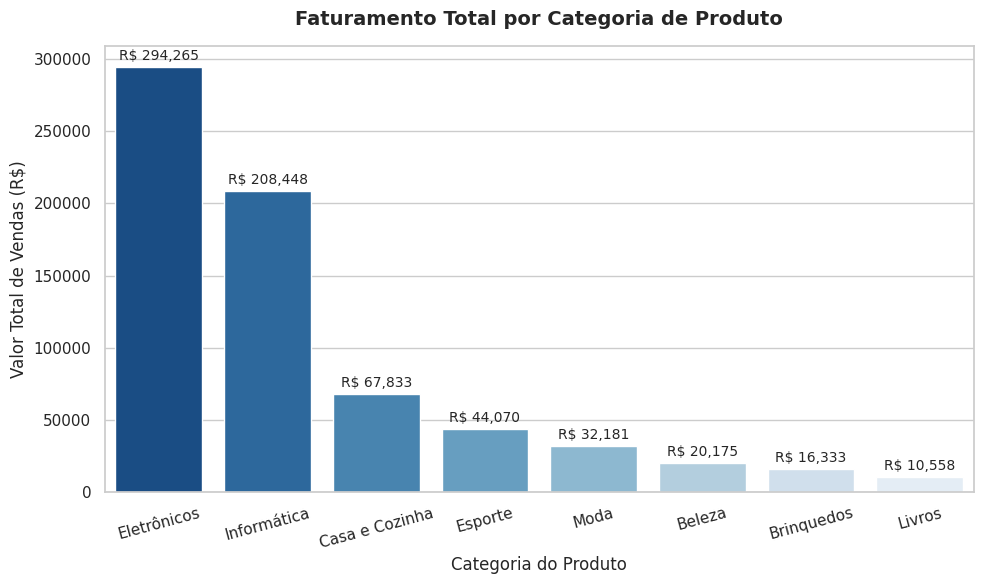

In [12]:
##Foco Geográfico: Direcionar campanhas de marketing e logística para as cidades com maior volume de vendas (ex: Rio de Janeiro e Curitiba).

##Gestão de Portfólio: Priorizar o estoque e parcerias na categoria de maior faturamento (Eletrônicos).

##Relacionamento com o Cliente: Criar estratégias de fidelização voltadas para o perfil demográfico predominante e para os clientes de maior valor acumulado (como o cliente ID C0041).

import matplotlib.pyplot as plt
import seaborn as sns

# Configuração do estilo do gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Agrupando os dados por categoria e somando o valor total
vendas_cat = df_limpo.groupby('categoria_produto')['valor_total'].sum().sort_values(ascending=False)

# Criando o gráfico de barras
ax = sns.barplot(x=vendas_cat.index, y=vendas_cat.values, palette='Blues_r')

# Títulos e rótulos
plt.title('Faturamento Total por Categoria de Produto', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Categoria do Produto', fontsize=12)
plt.ylabel('Valor Total de Vendas (R$)', fontsize=12)

# Formatando os valores em cima das barras
for p in ax.patches:
    ax.annotate(f'R$ {p.get_height():,.0f}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 8),
                textcoords='offset points', fontsize=10)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()




/tmp/ipykernel_2712/874326372.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=top_5_cidades.values, y=top_5_cidades.index, palette='Purples_r')


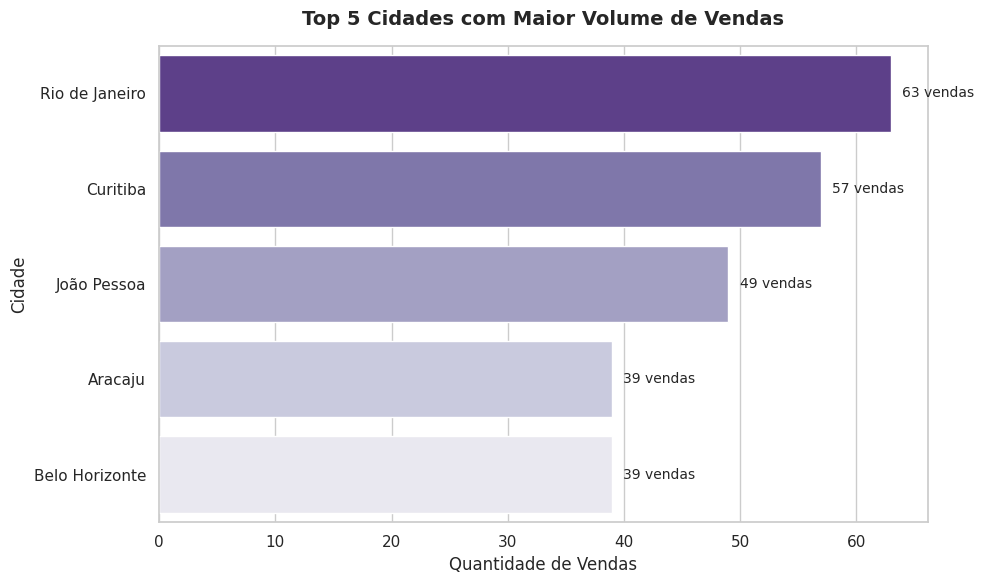

In [13]:
plt.figure(figsize=(10, 6))

# Pegando o Top 5 cidades com mais vendas
top_5_cidades = df_limpo['cidade'].value_counts().head(5)

# Criando o gráfico de barras horizontais
ax = sns.barplot(x=top_5_cidades.values, y=top_5_cidades.index, palette='Purples_r')

plt.title('Top 5 Cidades com Maior Volume de Vendas', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Quantidade de Vendas', fontsize=12)
plt.ylabel('Cidade', fontsize=12)

# Adicionando os números nas barras
for p in ax.patches:
    ax.annotate(f'{int(p.get_width())} vendas',
                (p.get_width(), p.get_y() + p.get_height() / 2.),
                ha='left', va='center',
                xytext=(8, 0),
                textcoords='offset points', fontsize=10)

plt.tight_layout()
plt.show()

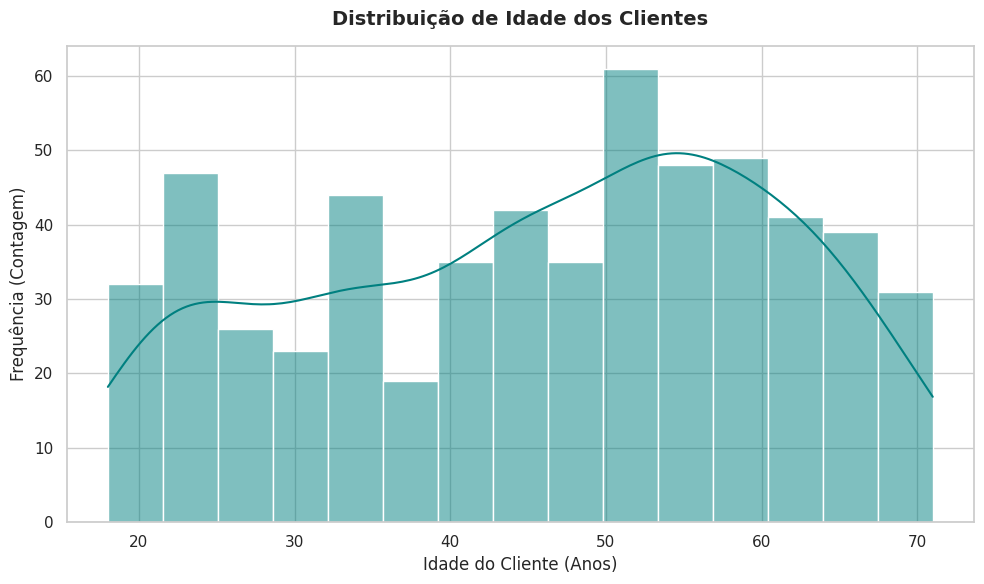

In [14]:
plt.figure(figsize=(10, 6))

# Criando o histograma com curva de densidade (KDE)
sns.histplot(df_limpo['idade_cliente'], bins=15, kde=True, color='teal')

plt.title('Distribuição de Idade dos Clientes', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Idade do Cliente (Anos)', fontsize=12)
plt.ylabel('Frequência (Contagem)', fontsize=12)

plt.tight_layout()
plt.show()